<a href="https://colab.research.google.com/github/Angelinat3/Machine-Learning2026/blob/main/JS07/JS07_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

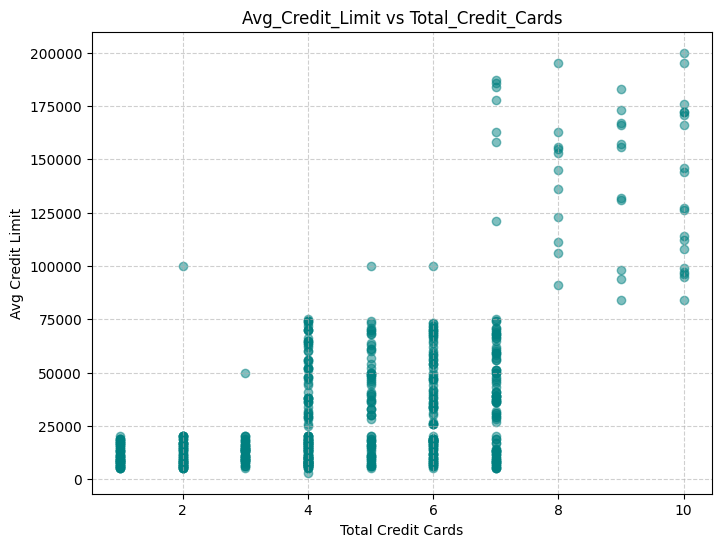

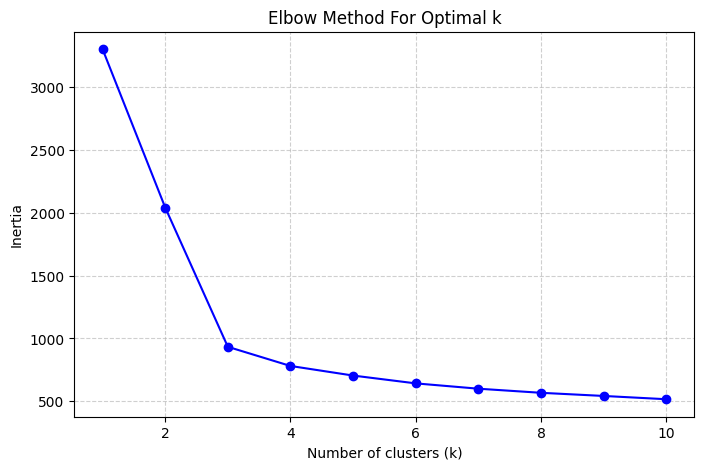

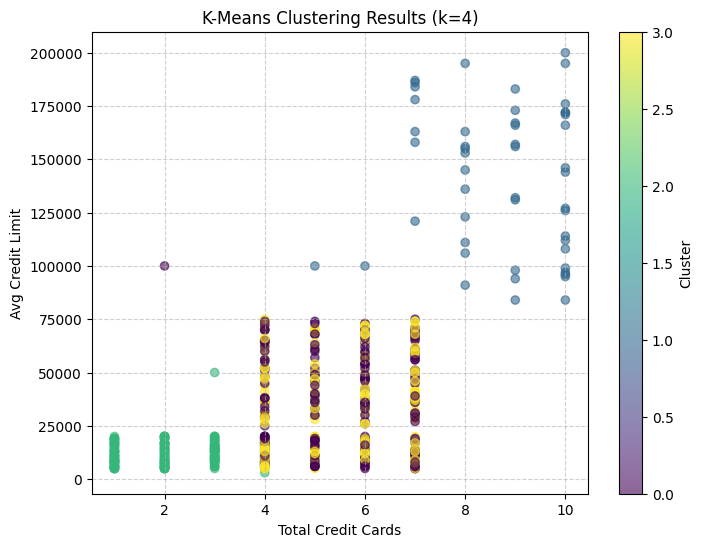

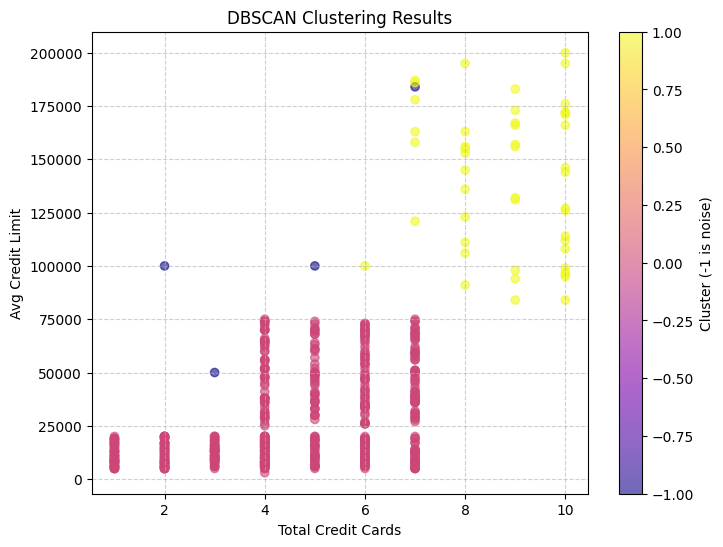

Jumlah klaster DBSCAN: 3
Silhouette Score (K-Means): 0.3556670619372605
DBI (K-Means): 1.1181747319588502
Silhouette Score (DBSCAN): 0.5723066186731014
DBI (DBSCAN): 0.6287828431175619


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import DBSCAN, KMeans
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

# 1. Load dataset
df = pd.read_csv("CC_Customer_Dataset.csv")

# 2. Scatterplot of Avg_Credit_Limit vs Total_Credit_Cards
plt.figure(figsize=(8, 6))
plt.scatter(
    df["Total_Credit_Cards"], df["Avg_Credit_Limit"], alpha=0.5, color="teal"
)
plt.title("Avg_Credit_Limit vs Total_Credit_Cards")
plt.xlabel("Total Credit Cards")
plt.ylabel("Avg Credit Limit")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 3. Fitur untuk klasterisasi
features = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made",
]
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 4. Elbow Method untuk K-Means
inertias = []
K = range(1, 11)
for k in K:
  kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
  kmeans.fit(X_scaled)
  inertias.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(K, inertias, marker="o", linestyle="-", color="b")
plt.title("Elbow Method For Optimal k")
plt.xlabel("Number of clusters (k)")
plt.ylabel("Inertia")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 5. K-Means Clustering dengan k optimal = 4
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)

# Scatter plot K-Means
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["Total_Credit_Cards"],
    df["Avg_Credit_Limit"],
    c=df["KMeans_Cluster"],
    cmap="viridis",
    alpha=0.6,
)
plt.title("K-Means Clustering Results (k=4)")
plt.xlabel("Total Credit Cards")
plt.ylabel("Avg Credit Limit")
plt.colorbar(scatter, label="Cluster")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 6. DBSCAN Clustering
dbscan = DBSCAN(eps=1.2, min_samples=5)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

# Scatter plot DBSCAN
plt.figure(figsize=(8, 6))
scatter = plt.scatter(
    df["Total_Credit_Cards"],
    df["Avg_Credit_Limit"],
    c=df["DBSCAN_Cluster"],
    cmap="plasma",
    alpha=0.6,
)
plt.title("DBSCAN Clustering Results")
plt.xlabel("Total Credit Cards")
plt.ylabel("Avg Credit Limit")
plt.colorbar(scatter, label="Cluster (-1 is noise)")
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

# 7. Evaluasi Metrik (Silhouette Score & Davies-Bouldin Index)
labels = df["DBSCAN_Cluster"]
n_clusters_db = len(set(labels)) - (1 if -1 in labels else 0)

print(f"Jumlah klaster DBSCAN: {n_clusters_db}")
print(
    "Silhouette Score (K-Means):",
    silhouette_score(X_scaled, df["KMeans_Cluster"]),
)
print("DBI (K-Means):", davies_bouldin_score(X_scaled, df["KMeans_Cluster"]))

mask = labels != -1
if mask.sum() > 1 and len(set(labels[mask])) > 1:
  print("Silhouette Score (DBSCAN):", silhouette_score(X_scaled[mask], labels[mask]))
  print("DBI (DBSCAN):", davies_bouldin_score(X_scaled[mask], labels[mask]))